# Experiment 10 — Does pretraining help at the same learning rate?

**Answer:** on this split and seed, full fine-tuning (09) beats the matched scratch run (10) for both Si and O. This supports useful E/F initialisation under the matched recipe; it does not establish a multi-seed or best-tuned advantage.

Both use LR `1e-4`, the same architecture, data, loss, batch accumulation and 300-epoch budget. Their scheduler *rules* match; realised learning-rate paths may differ because validation drives the scheduler. Best checkpoints: 09 at epoch 295; 10 at epoch 288.

In [1]:
%matplotlib inline
from pathlib import Path
import os, sys
PROJECT = Path(os.environ.get('NEQUIP_PROJECT', '/Users/louismcauliffe/code/research/NequIP_experiments'))
REVIEW_DIR = Path(os.environ.get('NMR_REVIEW_DIR', str(PROJECT / 'experiments')))
sys.path.insert(0, str(REVIEW_DIR))
from scalar_transfer_review import *
CACHE = Path(os.environ.get('NEQUIP_EVAL_OUTPUT', str(PROJECT / 'experiments/10-12-evaluation-data')))
OUTPUT = REVIEW_DIR / '10-TensorNequIP-MSIsotropy-Scratch-Control-Evaluation-figures'
OUTPUT.mkdir(parents=True, exist_ok=True)
sites, metrics, structures, boot, provenance, manifest = load_review(PROJECT, CACHE)
overview(provenance, ['09', '10'])
print('Verified cached predictions: 800 training + 50 validation structures; test data excluded.')


,Selected epoch,Initial LR,Trainable parameters,Export matches checkpoint
Experiment,,,,
09,295,0.0001,738052,True
10,288,0.0001,738052,True


## 1 · How large is the improvement?
Dots show validation error; horizontal intervals resample whole structures. The paired difference, **09 minus 10**, is printed separately: negative values favour pretraining. MAE captures typical error; RMSE emphasises larger misses.

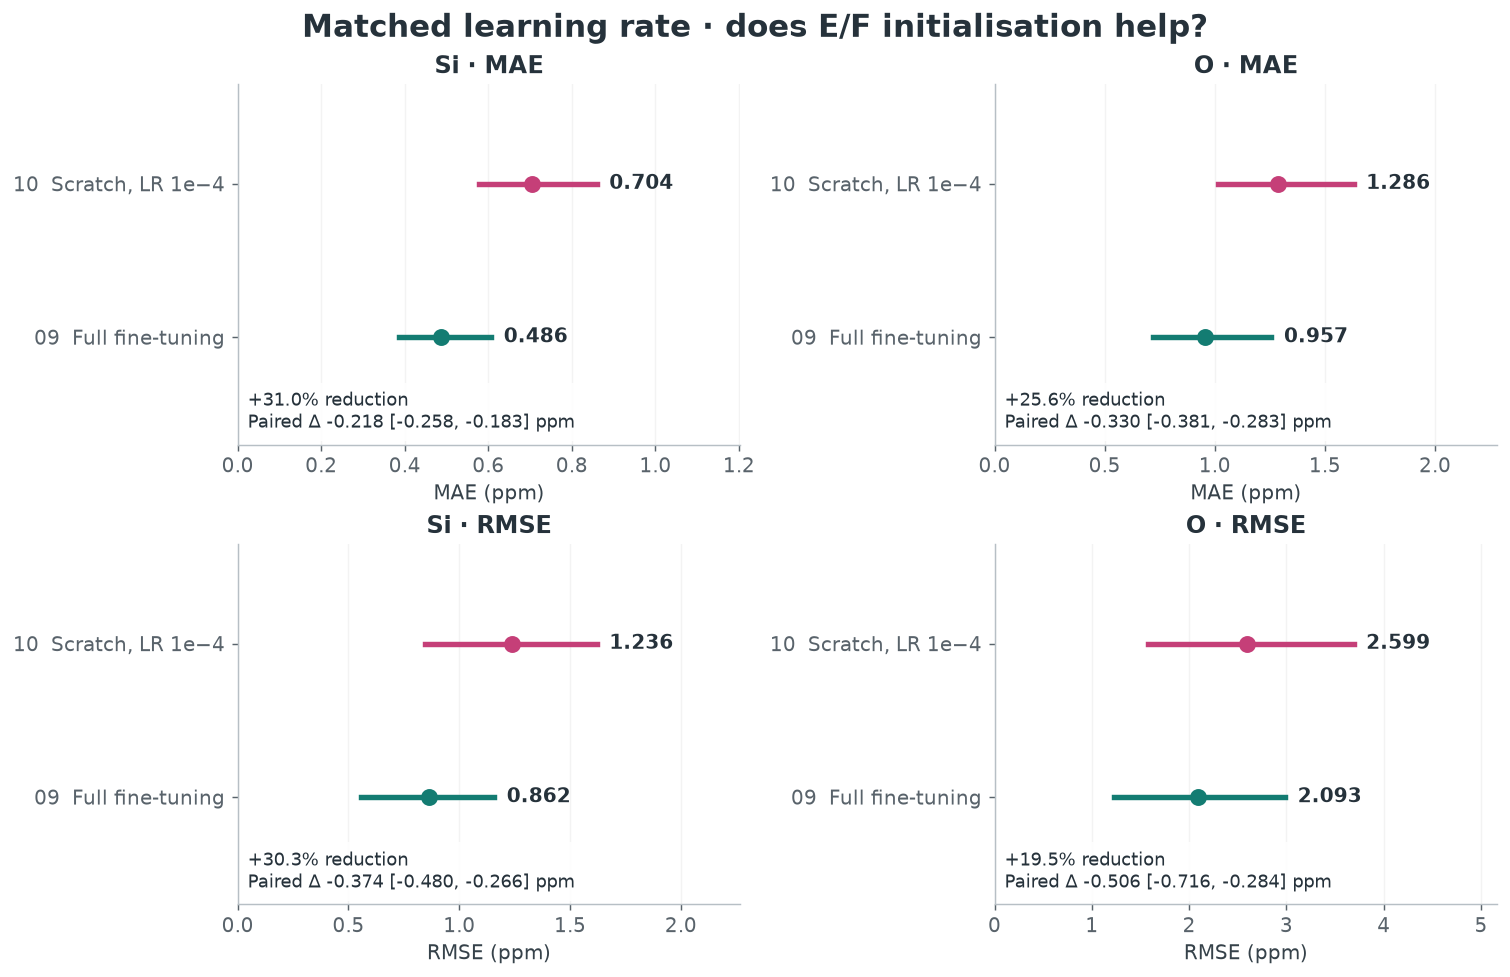

**Si MAE:** 0.704 → 0.486 ppm (31.0% lower with pretraining); paired 95% Δ [-0.258, -0.183] ppm.

**Si RMSE:** 1.236 → 0.862 ppm (30.3% lower with pretraining); paired 95% Δ [-0.480, -0.266] ppm.

**O MAE:** 1.286 → 0.957 ppm (25.6% lower with pretraining); paired 95% Δ [-0.381, -0.283] ppm.

**O RMSE:** 2.599 → 2.093 ppm (19.5% lower with pretraining); paired 95% Δ [-0.716, -0.284] ppm.

In [2]:
changes = paired_figure(metrics, boot, '10', '09', 'Matched learning rate · does E/F initialisation help?', OUTPUT, '01-matched-accuracy')
for r in changes.itertuples():
    display(Markdown(f'**{r.element} {r.metric}:** {r.old:.3f} → {r.new:.3f} ppm ({r.reduction_pct:.1f}% lower with pretraining); paired 95% Δ [{r.lower:+.3f}, {r.upper:+.3f}] ppm.'))

## 2 · Is the gain spread across structures?
Each point is one of the same 50 validation structures. Below the diagonal favours 09; amber points favour scratch. The two largest-error structures are labelled by their zero-based file index. No points are removed.

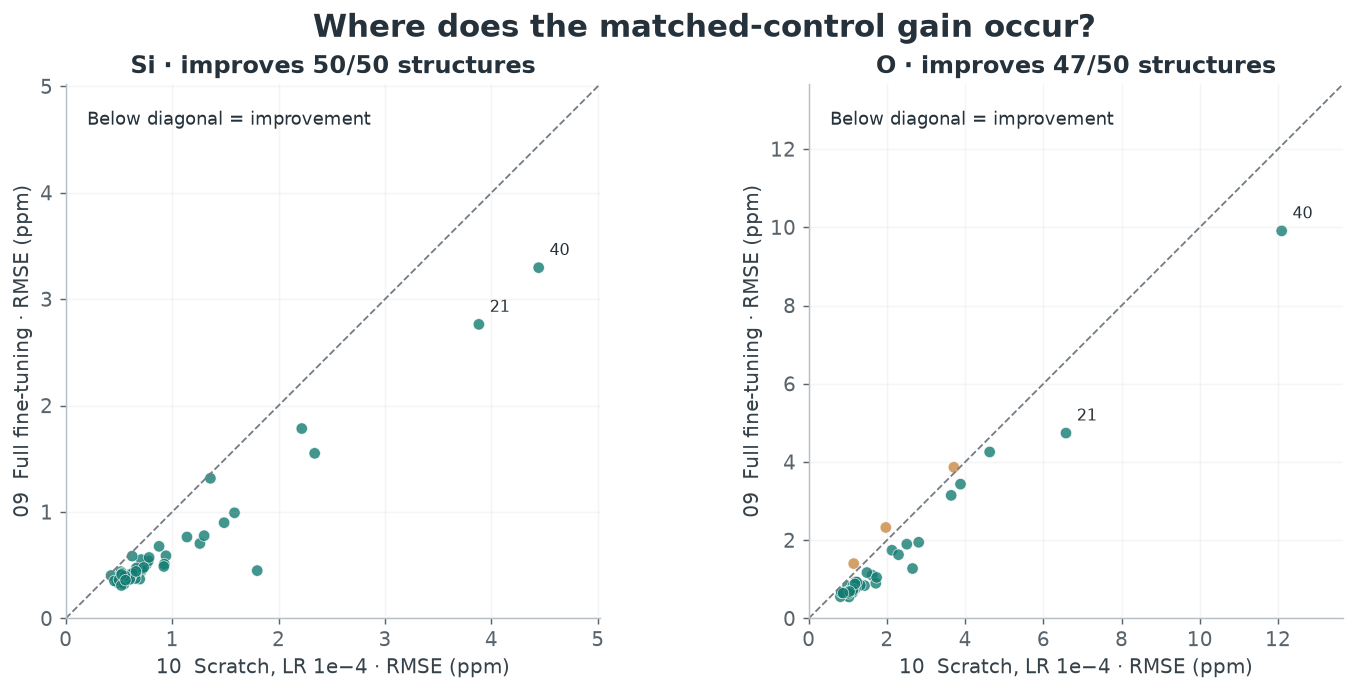

**Si:** 09 improves 50/50 structures. Structure 40 accounts for 22.6% of the net squared-error reduction.

**O:** 09 improves 47/50 structures. Structure 40 accounts for 40.5% of the net squared-error reduction.

split        train  valid
run element              
09  O        0.765  2.093
    Si       0.516  0.862
10  O        1.452  2.599
    Si       0.899  1.236

In [3]:
concentration = structure_figure(structures, '10', '09', 'Where does the matched-control gain occur?', OUTPUT, '02-structure-comparison')
for r in concentration.itertuples():
    display(Markdown(f'**{r.element}:** 09 improves {r.structures_improved}/50 structures. Structure {r.largest_contributor} accounts for {r.share_of_net_SSE_reduction_pct:.1f}% of the net squared-error reduction.'))
display(metrics[metrics.run.isin(['09','10'])].pivot(index=['run','element'], columns='split', values='RMSE').round(3))

**Interpretation / next step.** The training table evaluates the same selected checkpoints on all 800 training structures, so it distinguishes fitting error from the validation gap. The next attribution check is paired seed replication of 09 versus 10. This is evidence for the fixed `1e-4` recipe, not evidence that low-LR scratch is the best scratch baseline. Inspect per-element errors rather than pooled loss, and do not infer data efficiency from these full-data runs.

In [4]:
metrics[metrics.run.isin(['09', '10'])].to_csv(OUTPUT / 'metrics.csv', index=False)
provenance[provenance.run.isin(['09', '10'])].to_csv(OUTPUT / 'provenance.csv', index=False)
(OUTPUT / 'evaluation-manifest.json').write_text(json.dumps(manifest, indent=2))
assert len(list(OUTPUT.glob('*.png'))) == 2
print('Saved two figures as PNG/PDF, metric tables and provenance.')

**Scope.** Absolute DFT isotropic shielding in ppm; no experimental referencing. Every metric is unweighted and split by element. These 50 validation structures selected the checkpoints; they are development results, not an independent test. Paired 95% intervals use 4,000 whole-structure bootstrap resamples and assume independent structures. They do not cover seed variability, model selection or unresolved trajectory dependence. All runs use seed 42; no new training or test-set evaluation occurs here.

**Reproducibility.** The setup verifies dataset, configuration and checkpoint hashes before using the shared prediction cache. `scalar_transfer_evaluate.py` regenerates it from train/validation data if absent. The shared helper `scalar_transfer_review.py` renders the figures. Use the project's `.venv` kernel; keep these helpers beside the notebooks. Full epoch histories were not included in the transferred results, so no learning curves or claims of convergence are fabricated.